# Phase 2: tabular ANN vs spatial CNN for shot xG

**Question.** Does a neural net on 24 shot features, or a CNN on 360 player-position maps, predict goals better than a plain logistic regression, and are its probabilities calibrated?

**Data (Phase 1).** 10,233 open-play shots, split by match (train 7,290 / val 1,463 / test 1,480), about 10% goals.

**Rules of the notebook**
- Every choice (architecture, learning rate, stopping epoch, final config) is made on **validation**. **Test is opened once**, in section 6.
- The scaler is fitted on train rows only. Seeds are fixed. ANN and CNN results are mean ± sd over seeds.
- Metrics: log-loss (main), Brier score, AUC; calibration curves in section 6.
- Everything trains on the GPU. The data live on the GPU too (section 3).

**Contents:** 0 Setup · 1 Data · 2 Metrics and baselines · 3 Training utilities (GPU) · 4 ANN · 5 CNN · 6 Final comparison · 7 Notes for the report

## 0. Setup
Imports, device, seeding and chart style. `cudnn.deterministic` makes GPU runs repeatable (tiny speed cost).

In [1]:
import copy, os, time, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.deterministic = True        # repeatable GPU runs
RESULTS = "../results"; os.makedirs(RESULTS, exist_ok=True)

def set_seed(s):
    """Seed everything that feeds training: weight init, dropout, batch shuffling, flip augmentation."""
    torch.manual_seed(s); np.random.seed(s)
    if device.type == "cuda": torch.cuda.manual_seed_all(s)

print("torch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only")

torch 2.14.1+cu130 | device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
# Chart style: one fixed colour per model everywhere (colour follows the entity), thin lines,
# quiet grid, a legend whenever there are 2+ series, marker shape as a second cue besides colour.
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
COLORS  = {"logistic": "#2a78d6", "ANN": "#eb6834", "CNN": "#1baf7a"}     # blue / orange / aqua
MARKERS = {"logistic": "o", "ANN": "s", "CNN": "^"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlecolor": INK, "legend.labelcolor": INK2, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "lines.linewidth": 1.8, "figure.dpi": 110})

## 1. Data
Phase 1 files. Row *i* of `tabular.csv` and row *i* of `spatial.npz` are the same shot. The scaler is fitted on **train rows only**, so no val or test statistics leak into preprocessing.

In [3]:
tab  = pd.read_csv("../data/processed/tabular.csv")
X_sp = np.load("../data/processed/spatial.npz")["X"]     # (N, 6, 40, 60) float16: attackers, defenders, GK, shooter, visible area, distance to goal
assert (tab["row_idx"].values == np.arange(len(tab))).all() and len(X_sp) == len(tab)

non_features = ["row_idx", "shot_id", "match_id", "team", "player", "period", "minute", "split", "goal"]
feat_cols = [c for c in tab.columns if c not in non_features]      # tabular features; no outcome information
idx = {s: tab.index[tab["split"] == s].to_numpy() for s in ["train", "val", "test"]}

scaler = StandardScaler().fit(tab.loc[idx["train"], feat_cols])    # train rows only
X_tab  = scaler.transform(tab[feat_cols]).astype("float32")
y      = tab["goal"].to_numpy().astype("float32")
yv, yt = y[idx["val"]], y[idx["test"]]

print(len(feat_cols), "features |", X_sp.shape, "| shots per split:", {s: len(i) for s, i in idx.items()})

24 features | (10233, 6, 40, 60) | shots per split: {'train': 7290, 'val': 1463, 'test': 1480}


## 2. Metrics and baselines
- **Log-loss** scores the predicted probability itself (a confident mistake costs a lot). Main metric.
- **Brier score** is the mean squared error of the probability. **AUC** only measures ranking.
- *Constant* (always the training goal rate) is the "knows nothing" floor. **Logistic regression is the bar** the neural nets have to beat.

In [4]:
def evaluate(y_true, p):
    return {"log_loss": log_loss(y_true, p), "auc": roc_auc_score(y_true, p), "brier": brier_score_loss(y_true, p)}

def fmt(m):
    return {k: round(float(v), 4) for k, v in m.items()}

base_rate = y[idx["train"]].mean()
print("constant  val:", fmt(evaluate(yv, np.full(len(yv), base_rate))))

# named `logreg`, not `lr`, so it never collides with a learning-rate variable
logreg = LogisticRegression(max_iter=2000).fit(X_tab[idx["train"]], y[idx["train"]])
lg_v = logreg.predict_proba(X_tab[idx["val"]])[:, 1]
lg_t = logreg.predict_proba(X_tab[idx["test"]])[:, 1]               # kept for section 6, not inspected here
print("logistic  val:", fmt(evaluate(yv, lg_v)))

constant  val: {'log_loss': 0.3247, 'auc': 0.5, 'brier': 0.0898}
logistic  val: {'log_loss': 0.276, 'auc': 0.7797, 'brier': 0.0789}


**Takeaway.** Logistic regression on the shot features is a strong baseline (AUC about 0.78). A neural net only matters if it clearly beats it.

## 3. Training utilities (GPU)
- **`GpuLoader`** puts a whole split on the GPU once and serves batches from there (all splits together are about 300 MB). Optional random left-right flip for the CNN, on the training set only.
- **`train_model`**: Adam + `BCEWithLogitsLoss`. The model outputs a **logit**; the sigmoid is applied only in `predict`. Early stopping on **val log-loss**; the best epoch's weights are restored.
- No `pos_weight`: re-weighting goals would inflate the predicted probabilities and wreck calibration.

In [5]:
class GpuLoader:
    """Keeps a whole split on the GPU and yields (x, y) batches from there (no CPU->GPU copy per batch)."""
    def __init__(self, X, y, batch_size=128, shuffle=False, augment=False):
        assert not augment or X.ndim == 4, "flip augmentation is only defined for (N, C, H, W) maps"
        self.X = torch.from_numpy(np.ascontiguousarray(X)).to(device)
        self.y = torch.from_numpy(np.ascontiguousarray(y)).to(device)
        self.dataset = self.y                          # so len(loader.dataset) works
        self.bs, self.shuffle, self.augment = batch_size, shuffle, augment
    def __len__(self):
        return (len(self.y) + self.bs - 1) // self.bs
    def __iter__(self):
        n = len(self.y)
        order = torch.randperm(n, device=device) if self.shuffle else torch.arange(n, device=device)
        for i in range(0, n, self.bs):
            ix = order[i:i + self.bs]
            xb = self.X[ix].float()                    # float16 storage -> float32 compute
            if self.augment:                           # mirror the y axis (left/right) for ~half of each batch
                flip = torch.rand(len(ix), device=device) < 0.5
                xb = torch.where(flip.view(-1, 1, 1, 1), xb.flip(2), xb)
            yield xb, self.y[ix]

def predict(model, loader):
    """Probabilities (numpy) in the loader's row order."""
    model.eval(); out = []
    with torch.no_grad():
        for xb, _ in loader:
            out.append(torch.sigmoid(model(xb)).cpu())   # logit -> probability happens here
    return torch.cat(out).numpy()

def train_model(model, train_dl, val_dl, lr=1e-3, weight_decay=0.0, max_epochs=200, patience=15):
    """Train with early stopping on val log-loss. Returns (best model, [(train_loss, val_logloss)], best epoch)."""
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()
    y_val = val_dl.y.cpu().numpy()
    best = {"ll": np.inf, "state": None, "epoch": 0}
    hist = []
    for epoch in range(1, max_epochs + 1):
        model.train(); total = 0.0                     # train() switches dropout / batch-norm to training mode
        for xb, yb in train_dl:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(yb)
        val_ll = log_loss(y_val, predict(model, val_dl))
        hist.append((total / len(train_dl.dataset), val_ll))
        if val_ll < best["ll"] - 1e-4:                 # improved
            best = {"ll": val_ll, "state": copy.deepcopy(model.state_dict()), "epoch": epoch}
        elif epoch - best["epoch"] >= patience:        # no improvement for `patience` epochs
            break
    model.load_state_dict(best["state"])               # back to the best epoch
    return model, hist, best["epoch"]

def plot_history(hist, best_ep, title, color):
    """Train loss vs val log-loss per epoch; dashed line = chosen (best) epoch."""
    h = np.array(hist); ep = np.arange(1, len(h) + 1)
    fig, ax = plt.subplots(figsize=(6, 3.4))
    ax.plot(ep, h[:, 0], color=INK2, label="train loss")
    ax.plot(ep, h[:, 1], color=color, label="val log-loss")
    ax.axvline(best_ep, color=MUTED, ls="--", lw=1)
    ax.set_xlabel("epoch"); ax.set_ylabel("log-loss"); ax.set_title(title, loc="left", fontsize=11)
    ax.legend(); plt.tight_layout(); plt.show()

def tab_loaders(bs=256):
    return (GpuLoader(X_tab[idx["train"]], y[idx["train"]], bs, shuffle=True),
            GpuLoader(X_tab[idx["val"]],   y[idx["val"]],   bs),
            GpuLoader(X_tab[idx["test"]],  y[idx["test"]],  bs))

## 4. ANN on tabular features
A small MLP (ReLU, dropout) on the scaled shot features, one logit out.

In [6]:
class ANN(nn.Module):
    def __init__(self, n_in, hidden=(64, 32), dropout=0.2):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers += [nn.Linear(d, 1)]                    # raw logit, no sigmoid (see train_model / predict)
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(1)

tab_train, tab_val, tab_test = tab_loaders()

### 4.1 First attempt: default configuration

best epoch: 9 | ANN default  val: {'log_loss': 0.2764, 'auc': 0.7795, 'brier': 0.0792}


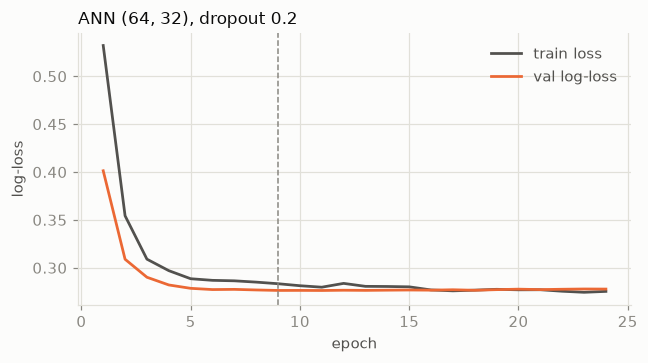

In [7]:
set_seed(42)
ann0, hist, best_ep = train_model(ANN(len(feat_cols), hidden=(64, 32), dropout=0.2), tab_train, tab_val)
print("best epoch:", best_ep, "| ANN default  val:", fmt(evaluate(yv, predict(ann0, tab_val))))
plot_history(hist, best_ep, "ANN (64, 32), dropout 0.2", COLORS["ANN"])

**Takeaway.** Val loss bottoms out after roughly 10 to 15 epochs and then rises: the net starts memorising quickly. Its score sits on top of the logistic baseline from section 2.

### 4.2 Hyperparameter search
3 hidden layouts × 2 dropouts × 2 learning rates, 3 seeds each, scored on **val** log-loss. Test is not used.

In [8]:
grid = {"hidden": [(32,), (64, 32), (128, 64)], "dropout": [0.1, 0.3], "lr": [1e-3, 3e-4]}

rows = []
for hidden, dropout, lr_ in itertools.product(grid["hidden"], grid["dropout"], grid["lr"]):
    lls, aucs, eps = [], [], []
    for seed in (0, 1, 2):
        set_seed(seed)
        m, _, ep = train_model(ANN(len(feat_cols), hidden, dropout), tab_train, tab_val, lr=lr_)
        met = evaluate(yv, predict(m, tab_val))
        lls.append(met["log_loss"]); aucs.append(met["auc"]); eps.append(ep)
    rows.append(dict(hidden=hidden, dropout=dropout, lr=lr_, ll=np.mean(lls), ll_sd=np.std(lls),
                     auc=np.mean(aucs), epoch=np.mean(eps)))

ann_grid = pd.DataFrame(rows).sort_values("ll")
ann_grid.to_csv(f"{RESULTS}/ann_grid.csv", index=False)
print(ann_grid.round(4).to_string(index=False))

   hidden  dropout     lr     ll  ll_sd    auc    epoch
    (32,)      0.3 0.0010 0.2765 0.0005 0.7770  30.3333
    (32,)      0.3 0.0003 0.2766 0.0007 0.7773 106.0000
(128, 64)      0.3 0.0010 0.2767 0.0008 0.7779   8.6667
(128, 64)      0.1 0.0010 0.2768 0.0005 0.7769   8.6667
(128, 64)      0.3 0.0003 0.2769 0.0008 0.7777  23.3333
    (32,)      0.1 0.0010 0.2770 0.0010 0.7753  30.3333
(128, 64)      0.1 0.0003 0.2771 0.0007 0.7768  15.6667
    (32,)      0.1 0.0003 0.2773 0.0011 0.7749  86.3333
 (64, 32)      0.3 0.0003 0.2775 0.0005 0.7764  51.0000
 (64, 32)      0.3 0.0010 0.2778 0.0007 0.7756  16.0000
 (64, 32)      0.1 0.0003 0.2780 0.0003 0.7745  37.6667
 (64, 32)      0.1 0.0010 0.2782 0.0004 0.7743  12.6667


**Takeaway.** All 12 configurations land within noise of each other (seed sd about 0.0005 to 0.001). Width, dropout and learning rate barely matter, so the ANN is limited by the **features**, not by model size.

### 4.3 Final ANN
**Selection rule (fixed before looking at test):** among configurations within seed noise of the best val log-loss, take the **simplest**.
Final: `hidden=(32,)`, dropout 0.3, lr 1e-3, trained on 5 seeds. Predictions are saved for section 6.

In [9]:
ANN_CFG = dict(hidden=(32,), dropout=0.3, lr=1e-3)

ann_v, ann_t = [], []
for seed in range(5):
    set_seed(seed)
    m, _, _ = train_model(ANN(len(feat_cols), ANN_CFG["hidden"], ANN_CFG["dropout"]), tab_train, tab_val, lr=ANN_CFG["lr"])
    ann_v.append(predict(m, tab_val)); ann_t.append(predict(m, tab_test))
ann_v, ann_t = np.array(ann_v), np.array(ann_t)
np.save(f"{RESULTS}/ann_val.npy", ann_v); np.save(f"{RESULTS}/ann_test.npy", ann_t)   # test predictions saved, not inspected here

ms = [evaluate(yv, p) for p in ann_v]
print("ANN final, val, 5 seeds:", {k: f"{np.mean([m[k] for m in ms]):.4f} ± {np.std([m[k] for m in ms]):.4f}" for k in ms[0]})

ANN final, val, 5 seeds: {'log_loss': '0.2769 ± 0.0005', 'auc': '0.7755 ± 0.0023', 'brier': '0.0792 ± 0.0001'}


## 5. CNN on player-position maps
Input `(6, 40, 60)`: 2-yard cells over the pitch, attacking toward the right. Channels: attackers, defenders, goalkeeper, shooter, **visible area**, distance to goal.
Visible area matters because the 360 camera only records players it can see: an empty cell means "no player" only where this channel is 1.

The CNN sees **only positions**. It gets none of the tabular features (body part, technique, play pattern, pressure).

In [10]:
# Data on the GPU: v1 trains on plain maps, v2 trains on randomly mirrored maps. Val/test are never flipped.
sp_train_v1 = GpuLoader(X_sp[idx["train"]], y[idx["train"]], 128, shuffle=True, augment=False)
sp_train    = GpuLoader(X_sp[idx["train"]], y[idx["train"]], 128, shuffle=True, augment=True)
sp_val      = GpuLoader(X_sp[idx["val"]],   y[idx["val"]],   128)
sp_test     = GpuLoader(X_sp[idx["test"]],  y[idx["test"]],  128)

### 5.1 First attempt: CNN v1
Three conv blocks, then flatten (2,240 values) into a dense layer of 64. No augmentation.

best epoch: 10 | CNN v1  val: {'log_loss': 0.2954, 'auc': 0.7327, 'brier': 0.0836}


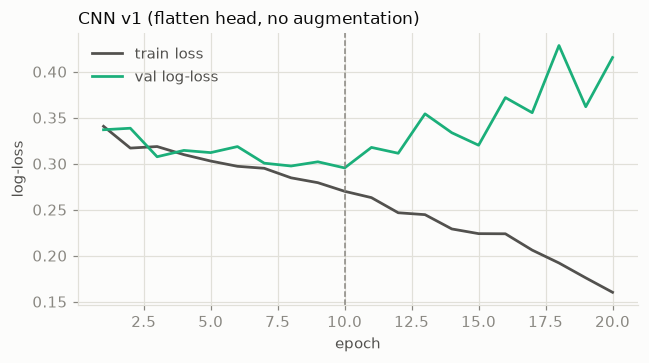

In [11]:
class CNNv1(nn.Module):
    """Kept for the record: the big flatten -> dense head has about 143k weights."""
    def __init__(self, ch=(16, 32, 64), k=3, dropout=0.3):
        super().__init__()
        layers, c_in = [], 6
        for c in ch:
            layers += [nn.Conv2d(c_in, c, k, padding=k // 2), nn.BatchNorm2d(c), nn.ReLU(), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*layers)
        with torch.no_grad():                                   # eval mode: dummy pass must not touch batch-norm statistics
            n = self.features.eval()(torch.zeros(1, 6, 40, 60)).numel()
        self.features.train()
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(n, 64), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)

set_seed(42)
cnn1, hist, best_ep = train_model(CNNv1(), sp_train_v1, sp_val, lr=1e-3, patience=10)
print("best epoch:", best_ep, "| CNN v1  val:", fmt(evaluate(yv, predict(cnn1, sp_val))))
plot_history(hist, best_ep, "CNN v1 (flatten head, no augmentation)", COLORS["CNN"])

**Takeaway.** Train loss keeps falling while val log-loss is jumpy and then blows up: the model **overfits**. The flatten → dense head has far more weights than the roughly 740 training goals can support, and val is barely better than the constant baseline.

### 5.2 CNN v2: fixes for the overfit
1. **Smaller head**: adaptive average pooling to 3×4, then a dense layer of 32 (about 12k weights instead of 143k).
2. **Left-right flip augmentation** on the training set only. The pitch is symmetric about y = 40 and the goal is centred there, so a mirrored shot is as realistic as the original. Val and test stay unflipped: they are the fixed yardstick.
3. Dropout 0.5, weight decay 1e-4, lower learning rate (3e-4).

best epoch: 26 | CNN v2  val: {'log_loss': 0.2926, 'auc': 0.7378, 'brier': 0.0828}


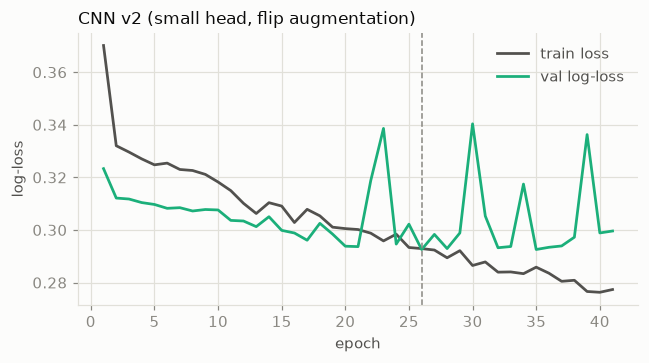

In [12]:
class CNN(nn.Module):
    def __init__(self, ch=(16, 32, 32), k=3, dropout=0.5, hidden=32):
        super().__init__()
        layers, c_in = [], 6
        for c in ch:
            layers += [nn.Conv2d(c_in, c, k, padding=k // 2), nn.BatchNorm2d(c), nn.ReLU(), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d((3, 4)), nn.Flatten(), nn.Dropout(dropout),
                                  nn.Linear(ch[-1] * 12, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1))
    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)

set_seed(42)
cnn2, hist, best_ep = train_model(CNN(), sp_train, sp_val, lr=3e-4, weight_decay=1e-4, patience=15)
print("best epoch:", best_ep, "| CNN v2  val:", fmt(evaluate(yv, predict(cnn2, sp_val))))
plot_history(hist, best_ep, "CNN v2 (small head, flip augmentation)", COLORS["CNN"])

**Takeaway.** Smoother val curve and a clearly lower val log-loss than v1: regularisation helped. It is still behind the tabular models, which is expected because it has to learn distance and angle from raw maps.

### 5.3 Search (one factor at a time)
A full grid is too slow, so each row changes **one** thing from the base (three blocks `(16, 32, 32)`, kernel 3, lr 3e-4), plus one combination. Same seeds and patience for every row, so the rows are comparable. Interactions between factors are not explored (a limitation to state in the report).

In [13]:
SEARCH_SEEDS = (0, 1)

def run_cnn(ch=(16, 32, 32), k=3, lr=3e-4, dropout=0.5, seeds=SEARCH_SEEDS, patience=15, max_epochs=120):
    ll, auc, ep = [], [], []
    for s in seeds:
        set_seed(s)
        m, _, e = train_model(CNN(ch, k, dropout), sp_train, sp_val, lr=lr, weight_decay=1e-4,
                              patience=patience, max_epochs=max_epochs)
        met = evaluate(yv, predict(m, sp_val))
        ll.append(met["log_loss"]); auc.append(met["auc"]); ep.append(e)
    return dict(ll=np.mean(ll), ll_sd=np.std(ll), auc=np.mean(auc), epoch=np.mean(ep))

base = dict(ch=(16, 32, 32), k=3, lr=3e-4)
trials = [base,
          {**base, "ch": (16, 32)},                  # fewer conv blocks
          {**base, "ch": (16,)},                     # one conv block
          {**base, "ch": (32, 64, 64)},              # wider
          {**base, "k": 5},                          # bigger kernel
          {**base, "lr": 1e-3},                      # higher learning rate
          {**base, "ch": (16, 32), "lr": 1e-3}]      # fewer blocks + higher lr

cnn_rows = []
for cfg in trials:
    t0 = time.time()
    cnn_rows.append({**cfg, **run_cnn(**cfg)})
    print({k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in cnn_rows[-1].items()},
          f"| {time.time() - t0:.0f}s")             # prints as each row finishes

cnn_search = pd.DataFrame(cnn_rows).sort_values("ll")
cnn_search.to_csv(f"{RESULTS}/cnn_search.csv", index=False)
cnn_search.round(4)

{'ch': (16, 32, 32), 'k': 3, 'lr': 0.0003, 'll': 0.2905, 'll_sd': 0.0013, 'auc': 0.7445, 'epoch': 28.0} | 23s
{'ch': (16, 32), 'k': 3, 'lr': 0.0003, 'll': 0.2856, 'll_sd': 0.0004, 'auc': 0.7524, 'epoch': 71.0} | 42s
{'ch': (16,), 'k': 3, 'lr': 0.0003, 'll': 0.3047, 'll_sd': 0.0002, 'auc': 0.6857, 'epoch': 118.0} | 46s
{'ch': (32, 64, 64), 'k': 3, 'lr': 0.0003, 'll': 0.2921, 'll_sd': 0.001, 'auc': 0.7444, 'epoch': 24.0} | 44s
{'ch': (16, 32, 32), 'k': 5, 'lr': 0.0003, 'll': 0.2985, 'll_sd': 0.0012, 'auc': 0.7134, 'epoch': 25.5} | 31s
{'ch': (16, 32, 32), 'k': 3, 'lr': 0.001, 'll': 0.2885, 'll_sd': 0.0009, 'auc': 0.7481, 'epoch': 15.0} | 19s
{'ch': (16, 32), 'k': 3, 'lr': 0.001, 'll': 0.2854, 'll_sd': 0.0008, 'auc': 0.7555, 'epoch': 53.5} | 35s


,ch,k,lr,ll,ll_sd,auc,epoch
6,"(16, 32)",3,0.0010,0.2854,0.0008,0.7555,53.5
1,"(16, 32)",3,0.0003,0.2856,0.0004,0.7524,71.0
5,"(16, 32, 32)",3,0.0010,0.2885,0.0009,0.7481,15.0
0,"(16, 32, 32)",3,0.0003,0.2905,0.0013,0.7445,28.0
3,"(32, 64, 64)",3,0.0003,0.2921,0.0010,0.7444,24.0
4,"(16, 32, 32)",5,0.0003,0.2985,0.0012,0.7134,25.5
2,"(16,)",3,0.0003,0.3047,0.0002,0.6857,118.0


**Takeaway.** *(Edit after reading the table above.)* Which change helped, which hurt, and whether the differences are bigger than the seed spread (`ll_sd`). Treat rows within about one `ll_sd` of each other as ties.

### 5.4 Final CNN
**Selection rule (same as for the ANN):** among configurations within seed noise of the best val log-loss, take the **simplest**. Set `CNN_CFG` from the table in 5.3, then train 5 seeds. Predictions are saved after every seed.

In [14]:
CNN_CFG = dict(ch=(16, 32), k=3, dropout=0.5, lr=3e-4)       # <- set from the 5.3 table

cnn_v, cnn_t = [], []
for seed in range(5):
    t0 = time.time(); set_seed(seed)
    m, _, ep = train_model(CNN(CNN_CFG["ch"], CNN_CFG["k"], CNN_CFG["dropout"]), sp_train, sp_val,
                           lr=CNN_CFG["lr"], weight_decay=1e-4, patience=15, max_epochs=120)
    cnn_v.append(predict(m, sp_val)); cnn_t.append(predict(m, sp_test))
    np.save(f"{RESULTS}/cnn_val.npy", np.array(cnn_v)); np.save(f"{RESULTS}/cnn_test.npy", np.array(cnn_t))   # saved after every seed
    print(f"seed {seed} | best epoch {ep} | {time.time() - t0:.0f}s | val", fmt(evaluate(yv, cnn_v[-1])))
cnn_v, cnn_t = np.array(cnn_v), np.array(cnn_t)

ms = [evaluate(yv, p) for p in cnn_v]
print("CNN final, val, 5 seeds:", {k: f"{np.mean([m[k] for m in ms]):.4f} ± {np.std([m[k] for m in ms]):.4f}" for k in ms[0]})

seed 0 | best epoch 81 | 36s | val {'log_loss': 0.2851, 'auc': 0.7543, 'brier': 0.0815}
seed 1 | best epoch 58 | 20s | val {'log_loss': 0.2864, 'auc': 0.7507, 'brier': 0.0816}
seed 2 | best epoch 116 | 48s | val {'log_loss': 0.2861, 'auc': 0.7511, 'brier': 0.0817}
seed 3 | best epoch 76 | 48s | val {'log_loss': 0.2864, 'auc': 0.7543, 'brier': 0.0821}
seed 4 | best epoch 75 | 48s | val {'log_loss': 0.2842, 'auc': 0.7569, 'brier': 0.0813}
CNN final, val, 5 seeds: {'log_loss': '0.2856 ± 0.0008', 'auc': '0.7535 ± 0.0023', 'brier': '0.0816 ± 0.0003'}


## 6. Final comparison: test is opened here, once
No model or setting changes after this section.

**Calibration plot.** Shots are binned by predicted probability (6 quantile bins). Each point compares the bin's mean prediction with its observed goal rate; on the dashed diagonal means well calibrated, below it overconfident, above it underconfident. With about 1,480 test shots each bin holds only about 15 goals, so small wiggles are noise: only systematic bends matter. ANN and CNN curves use predictions averaged over the seeds.

In [15]:
# reload saved predictions so this section also works after a kernel restart
ann_v, ann_t = np.load(f"{RESULTS}/ann_val.npy"), np.load(f"{RESULTS}/ann_test.npy")
cnn_v, cnn_t = np.load(f"{RESULTS}/cnn_val.npy"), np.load(f"{RESULTS}/cnn_test.npy")
print("seeds: ANN", len(ann_v), "| CNN", len(cnn_v))

def summarize(name, Pv, Pt):
    row = {"model": name}
    for split, P, yy in (("val", Pv, yv), ("test", Pt, yt)):
        ms = [evaluate(yy, p) for p in P]
        for k in ("log_loss", "auc", "brier"):
            v = [m[k] for m in ms]
            row[f"{split}_{k}"] = f"{np.mean(v):.4f}" + (f" ± {np.std(v):.4f}" if len(v) > 1 else "")
    return row

results = pd.DataFrame([
    summarize("constant", np.full((1, len(yv)), base_rate), np.full((1, len(yt)), base_rate)),
    summarize("logistic", lg_v[None], lg_t[None]),
    summarize("ANN", ann_v, ann_t),
    summarize("CNN", cnn_v, cnn_t)])
results.to_csv(f"{RESULTS}/phase2_results.csv", index=False)
results                                                     # the table doubles as the text version of the chart below

seeds: ANN 5 | CNN 5


,model,val_log_loss,val_auc,val_brier,test_log_loss,test_auc,test_brier
0,constant,0.3247,0.5000,0.0898,0.3295,0.5000,0.0916
1,logistic,0.2760,0.7797,0.0789,0.2799,0.7802,0.0806
2,ANN,0.2769 ± 0.0005,0.7755 ± 0.0023,0.0792 ± 0.0001,0.2802 ± 0.0015,0.7799 ± 0.0042,0.0810 ± 0.0004
3,CNN,0.2856 ± 0.0008,0.7535 ± 0.0023,0.0816 ± 0.0003,0.2864 ± 0.0015,0.7618 ± 0.0046,0.0819 ± 0.0004


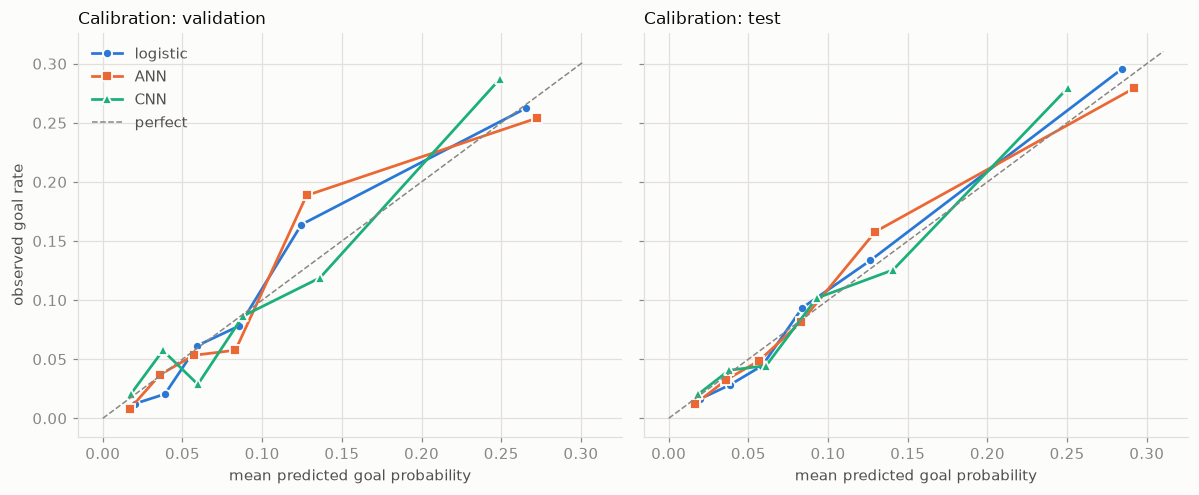

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
panels = [("validation", yv, {"logistic": lg_v, "ANN": ann_v.mean(0), "CNN": cnn_v.mean(0)}),
          ("test",       yt, {"logistic": lg_t, "ANN": ann_t.mean(0), "CNN": cnn_t.mean(0)})]
for ax, (title, yy, P) in zip(axes, panels):
    hi = 0.0
    for name, p in P.items():
        frac, mean_p = calibration_curve(yy, p, n_bins=6, strategy="quantile")
        ax.plot(mean_p, frac, marker=MARKERS[name], ms=6, color=COLORS[name], label=name,
                markeredgecolor=SURFACE, markeredgewidth=1.2)
        hi = max(hi, mean_p.max(), frac.max())
    ax.plot([0, hi * 1.05], [0, hi * 1.05], ls="--", lw=1, color=MUTED, label="perfect")
    ax.set_title(f"Calibration: {title}", loc="left", fontsize=11)
    ax.set_xlabel("mean predicted goal probability")
axes[0].set_ylabel("observed goal rate"); axes[0].legend(loc="upper left")
plt.tight_layout(); plt.savefig(f"{RESULTS}/calibration.png", dpi=150); plt.show()

### 6b. Is the difference real. 
 - Bootstrap on test

In [17]:
rng = np.random.default_rng(0)

# group test rows by match: shots from one match share teams, pitch and camera, so they aren't independent
mid = tab.loc[idx["test"], "match_id"].to_numpy()
groups = {m: np.where(mid == m)[0] for m in np.unique(mid)}
keys = list(groups)

P = {"logistic": lg_t, "ANN": ann_t.mean(0), "CNN": cnn_t.mean(0)}       # ANN/CNN: seed-averaged predictions
def per_shot_ll(p):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -(yt * np.log(p) + (1 - yt) * np.log(1 - p))
LL = {k: per_shot_ll(p) for k, p in P.items()}

pairs = [("ANN", "logistic"), ("CNN", "ANN"), ("CNN", "logistic")]
diff = {pr: {"ll": [], "auc": []} for pr in pairs}
for _ in range(2000):
    ix = np.concatenate([groups[k] for k in rng.choice(keys, len(keys))])   # resample MATCHES with replacement
    if yt[ix].min() == yt[ix].max():                                        # need both classes for AUC
        continue
    auc = {k: roc_auc_score(yt[ix], p[ix]) for k, p in P.items()}
    for a, b in pairs:                                                      # same resample for both models = paired
        diff[(a, b)]["ll"].append(LL[a][ix].mean() - LL[b][ix].mean())
        diff[(a, b)]["auc"].append(auc[a] - auc[b])

rows = []
for (a, b), d in diff.items():
    for metric in ("ll", "auc"):
        v = np.array(d[metric]); lo, hi = np.percentile(v, [2.5, 97.5])
        rows.append({"comparison": f"{a} − {b}", "metric": metric, "mean diff": v.mean(),
                     "95% CI": f"[{lo:+.4f}, {hi:+.4f}]", "CI excludes 0": bool(lo > 0 or hi < 0)})
boot = pd.DataFrame(rows).round(4)
boot.to_csv(f"{RESULTS}/bootstrap_test.csv", index=False)
boot

,comparison,metric,mean diff,95% CI,CI excludes 0
0,ANN − logistic,ll,-0.0007,"[-0.0045, +0.0030]",False
1,ANN − logistic,auc,0.0030,"[-0.0073, +0.0145]",False
2,CNN − ANN,ll,0.0062,"[-0.0021, +0.0143]",False
3,CNN − ANN,auc,-0.0189,"[-0.0426, +0.0039]",False
4,CNN − logistic,ll,0.0055,"[-0.0029, +0.0138]",False
5,CNN − logistic,auc,-0.0158,"[-0.0376, +0.0069]",False


## 7. Notes for the report
- **Selection.** Everything was chosen on validation log-loss, using mean over seeds, with the rule "simplest configuration within seed noise of the best". Test was evaluated once, in section 6.
- **Noise.** Val and test each contain only about 150 goals, so differences below roughly 0.003 log-loss are within noise. The seed spread (±) is reported for ANN and CNN; logistic regression is deterministic.
- **ANN vs logistic.** The grid showed no sensitivity to capacity, dropout or learning rate: the tabular features cap performance, not the model.
- **CNN.** v1 overfit (large flatten head, no augmentation); v2 added a small head, mirror augmentation and stronger regularisation. The search was one factor at a time, so interactions were not explored. The CNN sees only positions, not body part, technique, play pattern or pressure.
- **Calibration.** No `pos_weight` or resampling was used, so probabilities are not distorted by the 10% goal rate. See the calibration plot for any remaining bias.
- **Reproducibility.** Fixed seeds (`set_seed`), `cudnn.deterministic=True`, trained on an RTX 4060 (CUDA). Predictions are saved in `results/` (`ann_*.npy`, `cnn_*.npy`); tables and the calibration figure are saved there too. GPU results can differ from CPU results in the third decimal.

In [18]:
import torch
print(torch.__version__, torch.cuda.is_available())

2.14.1+cu130 True
